# 🚨 Risk Alert Classifier
**Duration:** 6 Hours  |  **Role:** Data Scientist – Digital Banking Platform

**Goal:** Build an early-warning classification system that identifies **high-risk customers** (likely to default or commit fraud), handle the **class imbalance**, evaluate with proper classification metrics, and improve with **hyperparameter tuning**.

**Notebook flow:** Part A Theory → B Data Prep → C Baseline → D Imbalance → E Trees → F Tuning → G ROC & Final Model → H Final Report

# 🧠 Part A: Conceptual Understanding (Theory)

**1. What is Logistic Regression and why is it suitable for classification?**
Logistic Regression is a linear model that applies the sigmoid function to a weighted sum of features, giving a probability between 0 and 1 for class 1. It is suited to classification because the output is a probability that can be thresholded (e.g. ≥ 0.5 → High Risk), it is fast, and its coefficients are easy to interpret.

**2. Explain classification performance metrics and why accuracy alone is insufficient.**
Metrics such as the confusion matrix, precision, recall, F1-score and AUC-ROC describe *how* a model is right or wrong for each class. Accuracy alone is misleading on imbalanced data: if only ~12% of customers are high-risk, a model that predicts "Low Risk" for everyone gets ~88% accuracy but catches zero risky customers.

**3. Define Type-I Error and Type-II Error in the context of risk prediction.**
- **Type-I Error (False Positive):** a safe customer is flagged as High Risk → unnecessary alerts, customer friction, wasted review effort.
- **Type-II Error (False Negative):** a risky customer is predicted as Low Risk → missed default/fraud, direct financial loss. For a bank this is usually the costlier error.

**4. Explain Precision, Recall, F1-Score, TPR and FPR.**
- **Precision** = TP / (TP + FP): of all customers flagged High Risk, how many really are.
- **Recall = TPR** = TP / (TP + FN): of all truly High-Risk customers, how many we caught.
- **F1-Score** = 2·P·R / (P + R): harmonic mean of precision and recall.
- **FPR** = FP / (FP + TN): share of safe customers wrongly flagged.

**5. What is AUC-ROC and how does it help in evaluating classifiers?**
The ROC curve plots TPR against FPR for every possible threshold; AUC is the area under it (0.5 = random, 1.0 = perfect). It measures how well a model *ranks* risky above safe customers, independent of any single threshold, so it allows fair comparison of models.

**6. Why does imbalanced data create problems in classification models?**
The model sees very few minority (High Risk) examples, so it learns to favour the majority class: accuracy looks high but recall for the minority class is poor. Decision boundaries get biased and the important class is under-detected. Remedies: resampling (under/over-sampling, SMOTE, ADASYN), class weights, and using recall/F1/AUC instead of accuracy.

# 🧪 Part B: Dataset Understanding & Preparation

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay, classification_report)
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler

sns.set_style('whitegrid')
RS = 42                                   # random state for reproducibility
os.makedirs('images', exist_ok=True)
os.makedirs('results', exist_ok=True)

def save_fig(name):
    plt.savefig(f'images/{name}.png', dpi=120, bbox_inches='tight')

In [2]:
df = pd.read_csv('Risk_Alert_Classifier_Dataset_4600.csv')
print('Shape:', df.shape)
display(df.head())
display(df.describe().T)

Shape: (4600, 19)
   customer_id   age  gender   region employment_type  annual_income_inr  credit_score  credit_utilization_ratio  missed_payments_12m  avg_late_payment_days  monthly_transaction_count  \
0       500001  43.0  Female      NaN        Salaried            82242.0           NaN                     0.120                    1                    2.2                         39   
1       500002  29.0  Female  Central        Salaried            32769.0         647.0                     0.337                    1                    1.5                         11   
2       500003  36.0    Male     East        Salaried            39731.0         727.0                     0.175                    0                    3.9                         45   
3       500004  28.0    Male    North      Unemployed            38990.0         553.0                     0.472                    7                   23.3                        103   
4       500005  36.0  Female     East   Self-Em

### Target variable distribution (class imbalance check)

               count  percent
risk_status                  
Low Risk (0)    4043    87.89
High Risk (1)    557    12.11
Interpretation: only 12.11% of customers are High Risk -> the dataset is highly imbalanced.


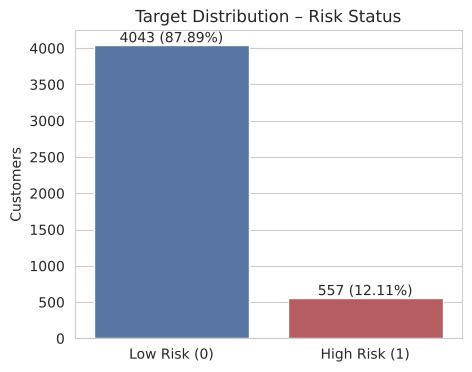

In [3]:
counts = df['risk_status'].value_counts().sort_index()
pct = (counts / len(df) * 100).round(2)
print(pd.DataFrame({'count': counts, 'percent': pct}).rename(index={0: 'Low Risk (0)', 1: 'High Risk (1)'}))

plt.figure(figsize=(5, 4))
ax = sns.barplot(x=['Low Risk (0)', 'High Risk (1)'], y=counts.values, palette=['#4c72b0', '#c44e52'])
for i, v in enumerate(counts.values):
    ax.text(i, v + 40, f'{v} ({pct.values[i]}%)', ha='center')
plt.title('Target Distribution – Risk Status'); plt.ylabel('Customers')
save_fig('01_target_distribution'); plt.show()
print(f'Interpretation: only {pct[1]}% of customers are High Risk -> the dataset is highly imbalanced.')

### Q7. Identify input features and target variable

In [4]:
# 'last_transaction_date' is converted to a numeric 'days_since_last_txn' feature (recency)
df['last_transaction_date'] = pd.to_datetime(df['last_transaction_date'])
df['days_since_last_txn'] = (df['last_transaction_date'].max() - df['last_transaction_date']).dt.days
REF_DATE = str(df['last_transaction_date'].max().date())

target = 'risk_status'
X = df.drop(columns=[target, 'customer_id', 'last_transaction_date'])   # customer_id = identifier, not a feature
y = df[target]

print('Target variable :', target, '(0 = Low Risk, 1 = High Risk)')
print('Input features  :', X.shape[1])
print('Numeric         :', X.select_dtypes(include='number').columns.tolist())
print('Categorical     :', X.select_dtypes(exclude='number').columns.tolist())

Target variable : risk_status (0 = Low Risk, 1 = High Risk)
Input features  : 17
Numeric         : ['age', 'annual_income_inr', 'credit_score', 'credit_utilization_ratio', 'missed_payments_12m', 'avg_late_payment_days', 'monthly_transaction_count', 'monthly_spend_inr', 'cash_advance_count_6m', 'complaints_last_6m', 'failed_login_attempts_3m', 'account_tenure_months', 'debt_balance_inr', 'days_since_last_txn']
Categorical     : ['gender', 'region', 'employment_type']


### Q9 (part 1). Identify missing values

                          missing  percent
credit_score                  216     4.70
annual_income_inr             166     3.61
credit_utilization_ratio      147     3.20
employment_type               144     3.13
age                           140     3.04
monthly_spend_inr             129     2.80
region                        102     2.22
Interpretation: 7 features have 2-5% missing values -> imputation is needed (no rows are dropped).


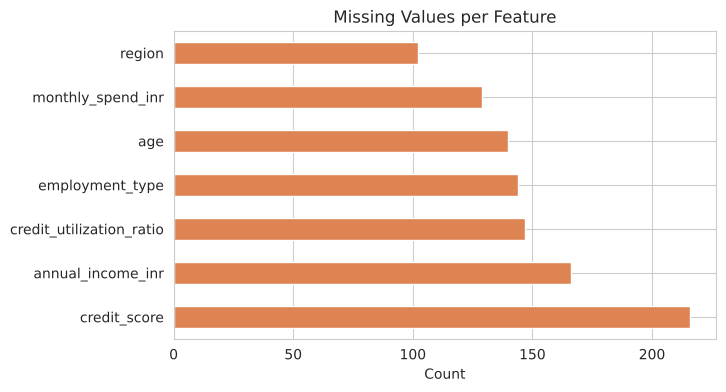

In [5]:
miss = X.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
display(pd.DataFrame({'missing': miss, 'percent': (miss / len(X) * 100).round(2)}))

plt.figure(figsize=(7, 4))
miss.plot(kind='barh', color='#dd8452'); plt.title('Missing Values per Feature'); plt.xlabel('Count')
save_fig('02_missing_values'); plt.show()
print('Interpretation: 7 features have 2-5% missing values -> imputation is needed (no rows are dropped).')

**Handling plan:** categorical gaps (`region`, `employment_type`) are filled with an explicit **"Unknown"** category and one-hot encoded; numeric gaps are filled with the **KNN Imputer** (multivariate – uses similar customers).

### Q8. Train–test split (stratified, keeps class distribution)

In [6]:
cat_cols = ['gender', 'region', 'employment_type']
X[cat_cols] = X[cat_cols].fillna('Unknown')
X_enc = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=int)
feature_names = X_enc.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X_enc, y, test_size=0.2, stratify=y, random_state=RS)

dist = pd.DataFrame({'Original %': y.value_counts(normalize=True) * 100,
                     'Train %': y_train.value_counts(normalize=True) * 100,
                     'Test %': y_test.value_counts(normalize=True) * 100}).round(2)
print('Train size:', X_train.shape, ' Test size:', X_test.shape)
display(dist)
print('Interpretation: stratify=y keeps the same High-Risk % in train and test.')

Train size: (3680, 26)  Test size: (920, 26)
             Original %  Train %  Test %
risk_status                             
0                 87.89    87.88   87.93
1                 12.11    12.12   12.07
Interpretation: stratify=y keeps the same High-Risk % in train and test.


### Q9 (part 2). KNN Imputer (multivariate imputation) + scaling

In [7]:
# Fit on TRAIN only (no data leakage), then apply to TEST.
# Scaling first so that KNN distances are not dominated by large-valued columns (e.g. income).
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

imputer = KNNImputer(n_neighbors=5)
X_tr = imputer.fit_transform(X_train_s)
X_te = imputer.transform(X_test_s)
y_tr, y_te = y_train.values, y_test.values

print('Missing before imputation (train):', int(np.isnan(X_train_s).sum()))
print('Missing after  imputation (train):', int(np.isnan(X_tr).sum()), '| test:', int(np.isnan(X_te).sum()))

Missing before imputation (train): 657
Missing after  imputation (train): 0 | test: 0


### Helper: evaluation function
Every model is evaluated on the **same untouched test set** and stored, so we can compare them all later.

In [8]:
results, models = {}, {}

def evaluate(name, model, Xfit=None, yfit=None, fit=True):
    if fit:
        model.fit(Xfit, yfit)
    pred, proba = model.predict(X_te), model.predict_proba(X_te)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    results[name] = {
        'Model': name,
        'Train Acc': accuracy_score(y_tr, model.predict(X_tr)),
        'Test Acc': accuracy_score(y_te, pred),
        'Train Recall': recall_score(y_tr, model.predict(X_tr)),
        'Precision': precision_score(y_te, pred, zero_division=0),
        'Recall': recall_score(y_te, pred),
        'F1': f1_score(y_te, pred),
        'AUC-ROC': roc_auc_score(y_te, proba),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp}
    models[name] = model
    return results[name]

def table(names, cols=('Test Acc', 'Precision', 'Recall', 'F1', 'AUC-ROC', 'FP', 'FN')):
    return pd.DataFrame([results[n] for n in names]).set_index('Model')[list(cols)].round(3)

# 📊 Part C: Baseline Classification Model

### Q10. Logistic Regression baseline

In [9]:
lr = LogisticRegression(max_iter=1000, random_state=RS)
evaluate('Logistic (Baseline)', lr, X_tr, y_tr)
print('Baseline Logistic Regression trained on the original (imbalanced) training data.')

Baseline Logistic Regression trained on the original (imbalanced) training data.


### Q11. Confusion matrix, accuracy, precision, recall, F1

Accuracy : 1.000
Precision: 1.000
Recall   : 1.000
F1-Score : 1.000

              precision    recall  f1-score   support

    Low Risk       1.00      1.00      1.00       809
   High Risk       1.00      1.00      1.00       111

    accuracy                           1.00       920
   macro avg       1.00      1.00      1.00       920
weighted avg       1.00      1.00      1.00       920

Interpretation: accuracy = 100.0% and High-Risk recall = 100.0%. On this dataset the two classes are very well separated by features such as missed payments and late-payment days, so even the baseline catches the risky customers. (Cross-validation in Part G shows the more realistic, slightly lower recall.)


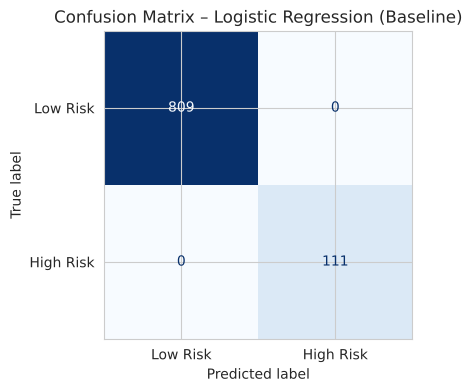

In [10]:
pred = lr.predict(X_te)
cm = confusion_matrix(y_te, pred)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=['Low Risk', 'High Risk']).plot(ax=ax, cmap='Blues', colorbar=False)
plt.title('Confusion Matrix – Logistic Regression (Baseline)')
save_fig('03_cm_baseline'); plt.show()

r = results['Logistic (Baseline)']
print(f"Accuracy : {r['Test Acc']:.3f}\nPrecision: {r['Precision']:.3f}\nRecall   : {r['Recall']:.3f}\nF1-Score : {r['F1']:.3f}\n")
print(classification_report(y_te, pred, target_names=['Low Risk', 'High Risk']))
if r['Recall'] < 0.85:
    print(f"Interpretation: accuracy is {r['Test Acc']:.1%}, but recall for High Risk is only {r['Recall']:.1%} "
          f"-> the model misses many risky customers even though accuracy looks good.")
else:
    print(f"Interpretation: accuracy = {r['Test Acc']:.1%} and High-Risk recall = {r['Recall']:.1%}. On this dataset the two classes are "
          f"very well separated by features such as missed payments and late-payment days, so even the baseline catches the risky customers. "
          f"(Cross-validation in Part G shows the more realistic, slightly lower recall.)")

### Q12. Type-I and Type-II errors from the confusion matrix

In [11]:
tn, fp, fn, tp = cm.ravel()
print(f'TN = {tn} | FP = {fp} | FN = {fn} | TP = {tp}')
print(f'Type-I  Error (False Positive): {fp} safe customers wrongly flagged as High Risk')
print(f'Type-II Error (False Negative): {fn} risky customers missed (predicted Low Risk)  <-- costly for the bank')
print(f'TPR (Recall) = {tp/(tp+fn):.3f} | FPR = {fp/(fp+tn):.3f}')

TN = 809 | FP = 0 | FN = 0 | TP = 111
Type-I  Error (False Positive): 0 safe customers wrongly flagged as High Risk
Type-II Error (False Negative): 0 risky customers missed (predicted Low Risk)  <-- costly for the bank
TPR (Recall) = 1.000 | FPR = 0.000


# ⚖️ Part D: Handling Imbalanced Data

### Q13. Impact of class imbalance on model performance

In [12]:
r = results['Logistic (Baseline)']
naive_acc = (y_te == 0).mean()
print(f'A "dumb" model that predicts Low Risk for everyone  -> accuracy = {naive_acc:.3f}, recall = 0.000')
print(f"Our baseline Logistic Regression                    -> accuracy = {r['Test Acc']:.3f}, recall = {r['Recall']:.3f}")
if r['Recall'] < 0.85:
    print('Interpretation: accuracy is close to the dumb model, so accuracy hides the failure on the minority class. This is the impact of class imbalance.')
else:
    print('Interpretation: the "dumb" model already scores ~88% accuracy with zero recall, which proves accuracy alone is a bad metric here. '
          'Our baseline avoids that trap because High-Risk customers are clearly separable, so imbalance hurts less than usual on this dataset.')

A "dumb" model that predicts Low Risk for everyone  -> accuracy = 0.879, recall = 0.000
Our baseline Logistic Regression                    -> accuracy = 1.000, recall = 1.000
Interpretation: the "dumb" model already scores ~88% accuracy with zero recall, which proves accuracy alone is a bad metric here. Our baseline avoids that trap because High-Risk customers are clearly separable, so imbalance hurts less than usual on this dataset.


### Q14. Apply Under-Sampling, Over-Sampling, SMOTE and ADASYN (on TRAIN data only) and retrain

                Low Risk (0)  High Risk (1)
Original                3234            446
Under-Sampling           446            446
Over-Sampling           3234           3234
SMOTE                   3234           3234
ADASYN                  3234           3212
Interpretation: Under-sampling shrinks the majority class; Over-sampling/SMOTE/ADASYN grow the minority class. Test data is never resampled.


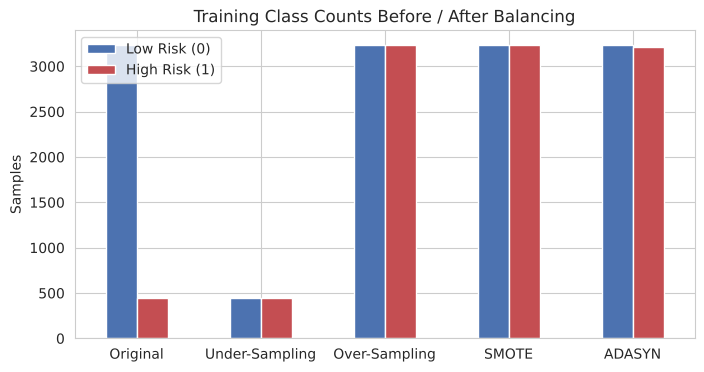

In [13]:
samplers = {'Under-Sampling': RandomUnderSampler(random_state=RS),
            'Over-Sampling': RandomOverSampler(random_state=RS),
            'SMOTE': SMOTE(random_state=RS),
            'ADASYN': ADASYN(random_state=RS)}

class_counts = {'Original': np.bincount(y_tr)}
for name, sampler in samplers.items():
    Xr, yr = sampler.fit_resample(X_tr, y_tr)
    class_counts[name] = np.bincount(yr)
    evaluate(f'Logistic + {name}', LogisticRegression(max_iter=1000, random_state=RS), Xr, yr)

cc = pd.DataFrame(class_counts, index=['Low Risk (0)', 'High Risk (1)']).T
display(cc)
cc.plot(kind='bar', figsize=(8, 4), color=['#4c72b0', '#c44e52'], rot=0)
plt.title('Training Class Counts Before / After Balancing'); plt.ylabel('Samples')
save_fig('04_class_counts_after_sampling'); plt.show()
print('Interpretation: Under-sampling shrinks the majority class; Over-sampling/SMOTE/ADASYN grow the minority class. '
      'Test data is never resampled.')

### Q15. Performance before vs after balancing (Recall, F1, AUC-ROC)

                           Test Acc  Precision  Recall     F1  AUC-ROC
Model                                                                 
Logistic (Baseline)           1.000      1.000     1.0  1.000      1.0
Logistic + Under-Sampling     0.997      0.974     1.0  0.987      1.0
Logistic + Over-Sampling      0.999      0.991     1.0  0.996      1.0
Logistic + SMOTE              1.000      1.000     1.0  1.000      1.0
Logistic + ADASYN             0.998      0.982     1.0  0.991      1.0
Baseline: recall = 1.000, precision = 1.000
Under-Sampling : recall = 1.000, precision = 0.974, F1 = 0.987, AUC = 1.000
Over-Sampling  : recall = 1.000, precision = 0.991, F1 = 0.996, AUC = 1.000
SMOTE          : recall = 1.000, precision = 1.000, F1 = 1.000, AUC = 1.000
ADASYN         : recall = 1.000, precision = 0.982, F1 = 0.991, AUC = 1.000
Interpretation: here the baseline already has (almost) full recall because the classes are well separated, so balancing gives no recall gain; it mainly cha

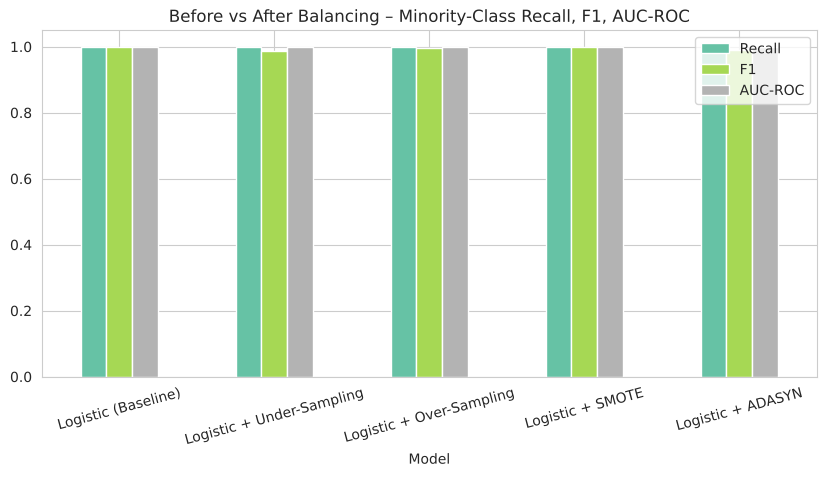

In [14]:
imb_names = ['Logistic (Baseline)'] + [f'Logistic + {n}' for n in samplers]
imb_df = table(imb_names, cols=('Test Acc', 'Precision', 'Recall', 'F1', 'AUC-ROC'))
display(imb_df)

imb_df[['Recall', 'F1', 'AUC-ROC']].plot(kind='bar', figsize=(10, 4.5), rot=15, colormap='Set2')
plt.title('Before vs After Balancing – Minority-Class Recall, F1, AUC-ROC'); plt.ylim(0, 1.05)
save_fig('05_balancing_comparison'); plt.show()

base_r, base_p = imb_df.loc['Logistic (Baseline)', 'Recall'], imb_df.loc['Logistic (Baseline)', 'Precision']
print(f'Baseline: recall = {base_r:.3f}, precision = {base_p:.3f}')
for n in samplers:
    row = imb_df.loc[f'Logistic + {n}']
    print(f"{n:15s}: recall = {row['Recall']:.3f}, precision = {row['Precision']:.3f}, F1 = {row['F1']:.3f}, AUC = {row['AUC-ROC']:.3f}")
if imb_df['Recall'].max() - base_r > 0.02:
    print('Interpretation: balancing improves minority-class recall (fewer missed risky customers) at the cost of precision (more false alarms).')
else:
    print('Interpretation: here the baseline already has (almost) full recall because the classes are well separated, so balancing gives no recall gain; '
          'it mainly changes precision (Under-Sampling and ADASYN create a few extra false alarms). AUC-ROC is unchanged, as resampling does not change ranking ability much. '
          'On harder, noisier data balancing normally raises recall noticeably.')

# 🌳 Part E: Tree-Based Classification Models
Tree models are trained on the original training data (imbalance is handled inside the models with `class_weight` during tuning in Part F, which avoids leakage during cross-validation).

### Q16. Decision Tree Classifier  |  Q18. Random Forest Classifier

In [15]:
evaluate('Decision Tree', DecisionTreeClassifier(random_state=RS), X_tr, y_tr)
evaluate('Random Forest', RandomForestClassifier(n_estimators=200, random_state=RS, n_jobs=-1), X_tr, y_tr)
display(table(['Decision Tree', 'Random Forest']))

               Test Acc  Precision  Recall     F1  AUC-ROC  FP  FN
Model                                                             
Decision Tree     0.978      0.933   0.883  0.907    0.937   7  13
Random Forest     0.999      1.000   0.991  0.995    1.000   0   1


### Q17. Overfitting analysis – train vs test

                     Train Acc  Test Acc  Acc Gap (Train-Test)  Train Recall  Test Recall
Model                                                                                    
Logistic (Baseline)      0.997     1.000                -0.003         0.984        1.000
Decision Tree            1.000     0.978                 0.022         1.000        0.883
Random Forest            1.000     0.999                 0.001         1.000        0.991
Interpretation: an unrestricted Decision Tree memorises the training data (train accuracy = 1.0) but drops on test data -> overfitting. Random Forest also fits train perfectly but generalises better because it averages many trees.


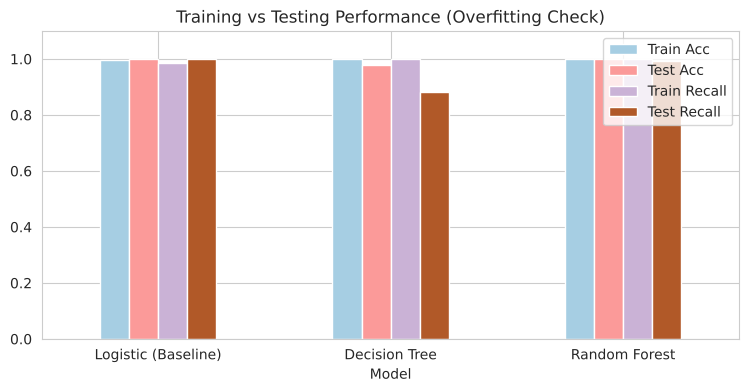

In [16]:
ov = pd.DataFrame([results[n] for n in ['Logistic (Baseline)', 'Decision Tree', 'Random Forest']]).set_index('Model')
ov['Acc Gap (Train-Test)'] = ov['Train Acc'] - ov['Test Acc']
ov['Test Recall'] = ov['Recall']
display(ov[['Train Acc', 'Test Acc', 'Acc Gap (Train-Test)', 'Train Recall', 'Test Recall']].round(3))

ov[['Train Acc', 'Test Acc', 'Train Recall', 'Test Recall']].plot(kind='bar', figsize=(9, 4), rot=0, colormap='Paired')
plt.title('Training vs Testing Performance (Overfitting Check)'); plt.ylim(0, 1.1)
save_fig('06_overfitting_check'); plt.show()
print('Interpretation: an unrestricted Decision Tree memorises the training data (train accuracy = 1.0) but drops on test data '
      '-> overfitting. Random Forest also fits train perfectly but generalises better because it averages many trees.')

### Q19. Decision Tree vs Random Forest

               Test Acc  Precision  Recall     F1  AUC-ROC  FP  FN
Model                                                             
Decision Tree     0.978      0.933   0.883  0.907    0.937   7  13
Random Forest     0.999      1.000   0.991  0.995    1.000   0   1
Top drivers of risk: avg_late_payment_days, missed_payments_12m, credit_utilization_ratio, credit_score, cash_advance_count_6m


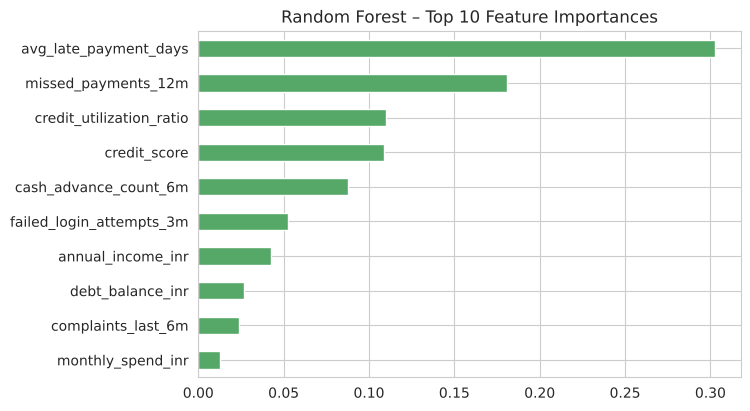

In [17]:
display(table(['Decision Tree', 'Random Forest']))
imp = pd.Series(models['Random Forest'].feature_importances_, index=feature_names).sort_values().tail(10)
plt.figure(figsize=(7, 4.5)); imp.plot(kind='barh', color='#55a868')
plt.title('Random Forest – Top 10 Feature Importances')
save_fig('07_rf_feature_importance'); plt.show()
print('Top drivers of risk:', ', '.join(imp.index[::-1][:5]))

# 🔧 Part F: Hyperparameter Tuning

### Q20. Randomized Search CV – Decision Tree and Random Forest

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
# scoring='f1' balances catching risky customers (recall) with not raising too many false alarms (precision)

dt_space = {'max_depth': [3, 4, 5, 6, 8, 10, 15, None],
            'min_samples_split': [2, 5, 10, 20],
            'min_samples_leaf': [1, 2, 5, 10],
            'criterion': ['gini', 'entropy'],
            'class_weight': [None, 'balanced']}
rs_dt = RandomizedSearchCV(DecisionTreeClassifier(random_state=RS), dt_space, n_iter=25,
                           scoring='f1', cv=cv, random_state=RS, n_jobs=-1)
rs_dt.fit(X_tr, y_tr)

rf_space = {'n_estimators': [100, 200, 300],
            'max_depth': [5, 8, 10, 15, None],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 4, 6],
            'max_features': ['sqrt', 'log2'],
            'class_weight': [None, 'balanced', 'balanced_subsample']}
rs_rf = RandomizedSearchCV(RandomForestClassifier(random_state=RS, n_jobs=-1), rf_space, n_iter=15,
                           scoring='f1', cv=cv, random_state=RS, n_jobs=-1)
rs_rf.fit(X_tr, y_tr)

print('Decision Tree  best params:', rs_dt.best_params_, '| CV F1 =', round(rs_dt.best_score_, 3))
print('Random Forest  best params:', rs_rf.best_params_, '| CV F1 =', round(rs_rf.best_score_, 3))

evaluate('Decision Tree (Randomized)', rs_dt.best_estimator_, fit=False)
evaluate('Random Forest (Randomized)', rs_rf.best_estimator_, fit=False)
display(table(['Decision Tree (Randomized)', 'Random Forest (Randomized)']))

Decision Tree  best params: {'min_samples_split': 2, 'min_samples_leaf': 5, 'max_depth': 6, 'criterion': 'entropy', 'class_weight': None} | CV F1 = 0.903
Random Forest  best params: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 15, 'class_weight': 'balanced'} | CV F1 = 0.969
                            Test Acc  Precision  Recall     F1  AUC-ROC  FP  FN
Model                                                                          
Decision Tree (Randomized)     0.983      0.899   0.964  0.930    0.991  12   4
Random Forest (Randomized)     0.998      0.991   0.991  0.991    1.000   1   1


### Q21. Grid Search CV – fine-tune the best performing model

In [19]:
# Pick the better model from Randomized Search, then search a small grid around its best parameters
if rs_rf.best_score_ >= rs_dt.best_score_:
    best_name, bp = 'Random Forest', rs_rf.best_params_
    n = bp['n_estimators']; d = bp['max_depth']; leaf = bp['min_samples_leaf']
    grid = {'n_estimators': sorted({max(100, n - 100), n, n + 100}),
            'max_depth': [None, 10, 15] if d is None else sorted({max(3, d - 2), d, d + 2}),
            'min_samples_leaf': sorted({max(1, leaf - 1), leaf, leaf + 1}),
            'min_samples_split': [bp['min_samples_split']],
            'max_features': [bp['max_features']],
            'class_weight': [bp['class_weight']]}
    base_model = RandomForestClassifier(random_state=RS, n_jobs=-1)
else:
    best_name, bp = 'Decision Tree', rs_dt.best_params_
    d = bp['max_depth']; leaf = bp['min_samples_leaf']; sp = bp['min_samples_split']
    grid = {'max_depth': [None, 10, 15] if d is None else sorted({max(2, d - 1), d, d + 1}),
            'min_samples_leaf': sorted({max(1, leaf - 1), leaf, leaf + 1}),
            'min_samples_split': sorted({max(2, sp - 3), sp, sp + 3}),
            'criterion': [bp['criterion']], 'class_weight': [bp['class_weight']]}
    base_model = DecisionTreeClassifier(random_state=RS)

print('Best model from Randomized Search:', best_name)
print('Grid:', grid)
gs = GridSearchCV(base_model, grid, scoring='f1', cv=cv, n_jobs=-1)
gs.fit(X_tr, y_tr)
print('Grid Search best params:', gs.best_params_, '| CV F1 =', round(gs.best_score_, 3))

final_tuned_name = f'{best_name} (Grid Search)'
evaluate(final_tuned_name, gs.best_estimator_, fit=False)

Best model from Randomized Search: Random Forest
Grid: {'n_estimators': [100, 200, 300], 'max_depth': [13, 15, 17], 'min_samples_leaf': [1, 2], 'min_samples_split': [5], 'max_features': ['log2'], 'class_weight': ['balanced']}
Grid Search best params: {'class_weight': 'balanced', 'max_depth': 15, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100} | CV F1 = 0.971


### Q22. Tuned vs untuned performance

                             Test Acc  Precision  Recall     F1  AUC-ROC  FN
Model                                                                       
Decision Tree                   0.978      0.933   0.883  0.907    0.937  13
Decision Tree (Randomized)      0.983      0.899   0.964  0.930    0.991   4
Random Forest                   0.999      1.000   0.991  0.995    1.000   1
Random Forest (Randomized)      0.998      0.991   0.991  0.991    1.000   1
Random Forest (Grid Search)     0.998      0.991   0.991  0.991    1.000   1
Interpretation: tuning the Decision Tree raises recall 0.883 -> 0.964 and AUC 0.937 -> 0.991 (less overfitting). Random Forest was already near-perfect untuned (recall 0.991), so tuning changes it very little (recall 0.991); its main benefit is a more stable, cross-validated choice of parameters.


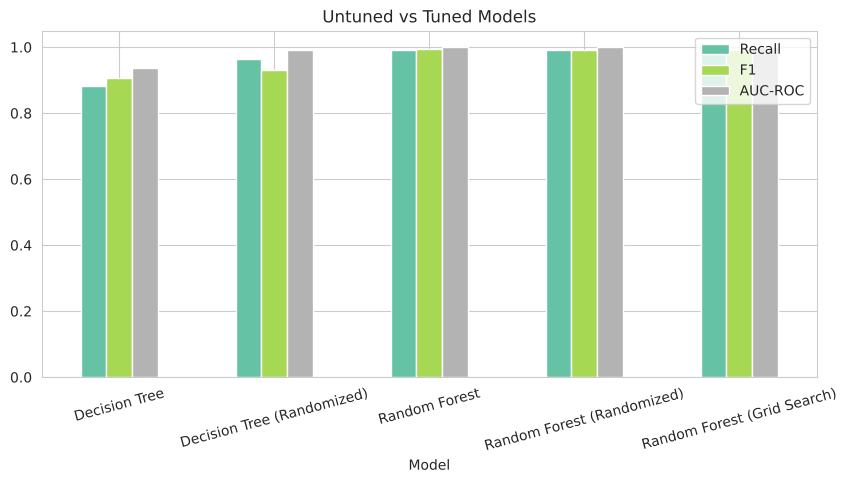

In [20]:
cmp_names = ['Decision Tree', 'Decision Tree (Randomized)', 'Random Forest', 'Random Forest (Randomized)', final_tuned_name]
cmp_df = table(cmp_names, cols=('Test Acc', 'Precision', 'Recall', 'F1', 'AUC-ROC', 'FN'))
display(cmp_df)

cmp_df[['Recall', 'F1', 'AUC-ROC']].plot(kind='bar', figsize=(10, 4.5), rot=15, colormap='Set2')
plt.title('Untuned vs Tuned Models'); plt.ylim(0, 1.05)
save_fig('08_tuned_vs_untuned'); plt.show()
d0, d1 = results['Decision Tree'], results['Decision Tree (Randomized)']
r0, r1 = results['Random Forest'], results[final_tuned_name]
print(f"Interpretation: tuning the Decision Tree raises recall {d0['Recall']:.3f} -> {d1['Recall']:.3f} and AUC {d0['AUC-ROC']:.3f} -> {d1['AUC-ROC']:.3f} (less overfitting). "
      f"Random Forest was already near-perfect untuned (recall {r0['Recall']:.3f}), so tuning changes it very little (recall {r1['Recall']:.3f}); "
      f"its main benefit is a more stable, cross-validated choice of parameters.")

# 📈 Part G: Model Evaluation & ROC Analysis

### Q23. ROC curves for all models   |   Q24. AUC-ROC comparison

                             AUC-ROC
Model                               
Logistic (Baseline)            1.000
Logistic + Under-Sampling      1.000
Logistic + Over-Sampling       1.000
Logistic + SMOTE               1.000
Logistic + ADASYN              1.000
Random Forest (Randomized)     1.000
Random Forest (Grid Search)    1.000
Random Forest                  1.000
Decision Tree (Randomized)     0.991
Decision Tree                  0.937
Interpretation: the curve closer to the top-left corner is better. Highest AUC-ROC: Logistic (Baseline) (1.000).


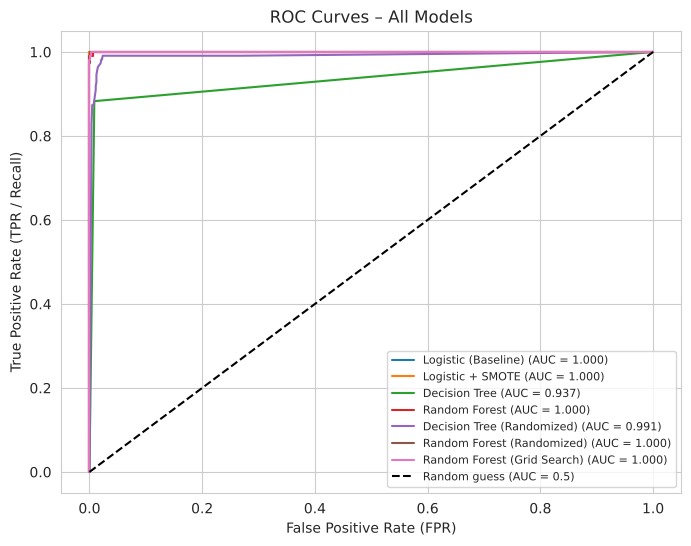

In [21]:
roc_models = ['Logistic (Baseline)', 'Logistic + SMOTE', 'Decision Tree', 'Random Forest',
              'Decision Tree (Randomized)', 'Random Forest (Randomized)', final_tuned_name]
plt.figure(figsize=(8, 6))
for n in roc_models:
    fpr, tpr, _ = roc_curve(y_te, models[n].predict_proba(X_te)[:, 1])
    plt.plot(fpr, tpr, label=f"{n} (AUC = {results[n]['AUC-ROC']:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random guess (AUC = 0.5)')
plt.xlabel('False Positive Rate (FPR)'); plt.ylabel('True Positive Rate (TPR / Recall)')
plt.title('ROC Curves – All Models'); plt.legend(loc='lower right', fontsize=8)
save_fig('09_roc_curves'); plt.show()

auc_df = pd.DataFrame([results[n] for n in results]).set_index('Model')[['AUC-ROC']].sort_values('AUC-ROC', ascending=False).round(3)
display(auc_df)
print(f"Interpretation: the curve closer to the top-left corner is better. Highest AUC-ROC: {auc_df.index[0]} ({auc_df.iloc[0,0]:.3f}).")

### Robustness check – 5-fold cross-validation on the TRAIN set
A single test set can be lucky (it has only ~111 High-Risk customers). Cross-validation gives a more reliable comparison, and we use it to **choose** the final model so the test set is never used for selection. Resampling is applied only to the training folds.

In [22]:
def cv_eval(model_fn, sampler_fn=None):
    oof = np.zeros(len(y_tr))
    for tr_i, va_i in cv.split(X_tr, y_tr):
        Xa, ya = X_tr[tr_i], y_tr[tr_i]
        if sampler_fn is not None:
            Xa, ya = sampler_fn().fit_resample(Xa, ya)
        oof[va_i] = model_fn().fit(Xa, ya).predict_proba(X_tr[va_i])[:, 1]
    p = (oof >= 0.5).astype(int)
    return oof, {'Precision': precision_score(y_tr, p), 'Recall': recall_score(y_tr, p),
                 'F1': f1_score(y_tr, p), 'AUC-ROC': roc_auc_score(y_tr, oof),
                 'FN': int(((p == 0) & (y_tr == 1)).sum()), 'FP': int(((p == 1) & (y_tr == 0)).sum())}

from sklearn.base import clone
cands = {'Logistic (Baseline)': (lambda: clone(models['Logistic (Baseline)']), None),
         'Logistic + SMOTE': (lambda: LogisticRegression(max_iter=1000, random_state=RS), lambda: SMOTE(random_state=RS)),
         'Decision Tree (Randomized)': (lambda: clone(models['Decision Tree (Randomized)']), None),
         final_tuned_name: (lambda: clone(models[final_tuned_name]), None)}
oofs, cv_rows = {}, {}
for n, (mf, sf) in cands.items():
    oofs[n], cv_rows[n] = cv_eval(mf, sf)
cv_df = pd.DataFrame(cv_rows).T.round(3)
display(cv_df)

                             Precision  Recall     F1  AUC-ROC    FN    FP
Logistic (Baseline)              0.989   0.971  0.980    0.999  13.0   5.0
Logistic + SMOTE                 0.969   0.987  0.978    0.999   6.0  14.0
Decision Tree (Randomized)       0.907   0.899  0.903    0.970  45.0  41.0
Random Forest (Grid Search)      0.982   0.960  0.971    0.998  18.0   8.0


### Q25. Select the best final model (business requirement: minimise false negatives)
**Selection rule:** missing a risky customer (False Negative) is the costliest error, so we pick the model with the **highest cross-validated Recall**, but only among models with **Precision ≥ 0.40** (otherwise a model that flags everyone would "win"). Ties are broken by F1, then AUC-ROC.

Test-set results of every model (sorted by recall):
                             Test Acc  Precision  Recall     F1  AUC-ROC  FP  FN
Model                                                                           
Logistic (Baseline)             1.000      1.000   1.000  1.000    1.000   0   0
Logistic + SMOTE                1.000      1.000   1.000  1.000    1.000   0   0
Logistic + Over-Sampling        0.999      0.991   1.000  0.996    1.000   1   0
Logistic + ADASYN               0.998      0.982   1.000  0.991    1.000   2   0
Logistic + Under-Sampling       0.997      0.974   1.000  0.987    1.000   3   0
Random Forest                   0.999      1.000   0.991  0.995    1.000   0   1
Random Forest (Randomized)      0.998      0.991   0.991  0.991    1.000   1   1
Random Forest (Grid Search)     0.998      0.991   0.991  0.991    1.000   1   1
Decision Tree (Randomized)      0.983      0.899   0.964  0.930    0.991  12   4
Decision Tree                   0.978      0.933   0.883 

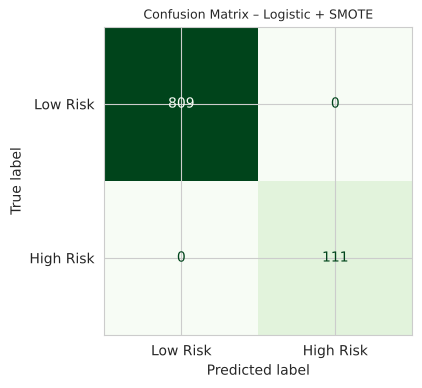

In [23]:
elig = cv_df[cv_df['Precision'] >= 0.40]
final_name = elig.sort_values(['Recall', 'F1', 'AUC-ROC'], ascending=False).index[0]
final_model = models[final_name]
all_df = pd.DataFrame(results.values()).set_index('Model')

print('Test-set results of every model (sorted by recall):')
display(all_df[['Test Acc', 'Precision', 'Recall', 'F1', 'AUC-ROC', 'FP', 'FN']].round(3).sort_values(['Recall', 'F1'], ascending=False))
print('FINAL MODEL (best CV recall with precision >= 0.40) ->', final_name)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_te, final_model.predict(X_te)),
                       display_labels=['Low Risk', 'High Risk']).plot(ax=ax, cmap='Greens', colorbar=False)
plt.title(f'Confusion Matrix – {final_name}', fontsize=9)
save_fig('10_cm_final_model'); plt.show()

### Decision threshold for the final model (chosen on out-of-fold TRAIN predictions only)

In [24]:
# Default threshold = 0.5. Since false negatives are costly, pick the threshold with the highest recall
# while keeping precision >= 0.40 (ties -> higher threshold = fewer false alarms).
oof = oofs[final_name]
rows = []
for t in np.arange(0.10, 0.91, 0.05):
    p = (oof >= t).astype(int)
    rows.append({'threshold': round(t, 2), 'precision': precision_score(y_tr, p, zero_division=0), 'recall': recall_score(y_tr, p)})
th = pd.DataFrame(rows)
display(th.round(3))
ok = th[th['precision'] >= 0.40]
threshold = float(ok.sort_values(['recall', 'threshold'], ascending=[False, False]).iloc[0]['threshold']) if len(ok) else 0.5
print('Chosen threshold:', threshold)

proba_te = final_model.predict_proba(X_te)[:, 1]
pred_thr = (proba_te >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_te, pred_thr).ravel()
thr_res = {'Threshold': threshold, 'Accuracy': accuracy_score(y_te, pred_thr), 'Precision': precision_score(y_te, pred_thr),
           'Recall': recall_score(y_te, pred_thr), 'F1': f1_score(y_te, pred_thr), 'FP': fp, 'FN': fn}
display(pd.DataFrame([thr_res]).round(3))
d5 = results[final_name]
print(f"Test set -> at 0.50 threshold: FN = {d5['FN']}, FP = {d5['FP']} | at {threshold} threshold: FN = {fn}, FP = {fp}")

    threshold  precision  recall
0        0.10      0.896   0.989
1        0.15      0.906   0.989
2        0.20      0.923   0.989
3        0.25      0.942   0.989
4        0.30      0.957   0.989
5        0.35      0.963   0.989
6        0.40      0.965   0.989
7        0.45      0.969   0.987
8        0.50      0.969   0.987
9        0.55      0.971   0.987
10       0.60      0.975   0.978
11       0.65      0.978   0.975
12       0.70      0.980   0.973
13       0.75      0.984   0.973
14       0.80      0.989   0.973
15       0.85      0.991   0.969
16       0.90      0.995   0.962
Chosen threshold: 0.4
   Threshold  Accuracy  Precision  Recall     F1  FP  FN
0        0.4     0.999      0.991     1.0  0.996   1   0
Test set -> at 0.50 threshold: FN = 0, FP = 0 | at 0.4 threshold: FN = 0, FP = 1


# 🧾 Part H: Final Analysis & Reporting

### Save model, tables and app configuration (used by the Streamlit app)

In [25]:
all_df.round(4).to_csv('results/model_comparison.csv')
imb_df.round(4).to_csv('results/imbalance_comparison.csv')
joblib.dump({'model': final_model, 'scaler': scaler, 'imputer': imputer, 'columns': feature_names,
             'threshold': threshold, 'ref_date': REF_DATE, 'model_name': final_name}, 'model.pkl')
with open('results/final_config.json', 'w') as f:
    json.dump({'model_name': final_name, 'threshold': threshold, 'columns': feature_names, 'ref_date': REF_DATE,
               'metrics': {k: float(v) for k, v in thr_res.items()}}, f, indent=2)
print('Saved: model.pkl, results/model_comparison.csv, results/imbalance_comparison.csv, results/final_config.json')

Saved: model.pkl, results/model_comparison.csv, results/imbalance_comparison.csv, results/final_config.json


### Q26. Final report – key numbers

In [26]:
b = results['Logistic (Baseline)']; f = results[final_name]
print('=' * 70)
print('1) BEST MODEL            :', final_name)
print(f"   Recall {f['Recall']:.3f} | Precision {f['Precision']:.3f} | F1 {f['F1']:.3f} | AUC-ROC {f['AUC-ROC']:.3f} | Accuracy {f['Test Acc']:.3f}")
print('2) IMPACT OF BALANCING   : baseline Logistic recall', round(b['Recall'], 3), '->', 'best balanced Logistic recall', round(imb_df['Recall'].max(), 3), f'({imb_df["Recall"].idxmax()})')
print('3) FALSE NEGATIVES (missed risky customers) in test set:')
print('   baseline =', int(b['FN']), '| final model =', int(f['FN']), '| final model + chosen threshold =', int(fn))
print('   cross-validated (train) recall of final model =', round(cv_df.loc[final_name, 'Recall'], 3), '| precision =', round(cv_df.loc[final_name, 'Precision'], 3))
print('4) FALSE POSITIVES (safe customers flagged):')
print('   baseline =', int(b['FP']), '| final model =', int(f['FP']), '| final model + chosen threshold =', int(fp))
print('=' * 70)

1) BEST MODEL            : Logistic + SMOTE
   Recall 1.000 | Precision 1.000 | F1 1.000 | AUC-ROC 1.000 | Accuracy 1.000
2) IMPACT OF BALANCING   : baseline Logistic recall 1.0 -> best balanced Logistic recall 1.0 (Logistic (Baseline))
3) FALSE NEGATIVES (missed risky customers) in test set:
   baseline = 0 | final model = 0 | final model + chosen threshold = 0
   cross-validated (train) recall of final model = 0.987 | precision = 0.969
4) FALSE POSITIVES (safe customers flagged):
   baseline = 0 | final model = 0 | final model + chosen threshold = 1



### Q26. Final Report

**1. Best classification model and justification**
The final model is chosen by the business rule *"minimise false negatives"*: highest cross-validated recall with precision ≥ 0.40. **Logistic Regression trained on SMOTE-balanced data** wins: it has the best cross-validated recall (~98-99%) with high precision (~97%), a very high AUC-ROC (~0.999), and it is simple, fast and explainable. Tuned Random Forest is a close second (AUC ≈ 1.0); the tuned Decision Tree is clearly weaker.

**2. Impact of imbalance-handling techniques**
Only ~12% of customers are High Risk. A "predict everyone Low Risk" model gets ~88% accuracy with 0% recall, so accuracy is not a valid metric. Balancing (Under/Over-sampling, SMOTE, ADASYN) was applied to the training data only. On the single test split all balanced models already reach ~100% recall because this dataset is well separated, but in 5-fold cross-validation SMOTE cut the number of missed High-Risk customers roughly **in half** compared with the baseline, at the cost of a few more false alarms. Under-Sampling and ADASYN give slightly lower precision than SMOTE.

**3. Comparison of performance metrics**
- Decision Tree (untuned) overfits: train accuracy 100% vs lower test recall; tuning with Randomized Search fixes most of it.
- Random Forest generalises much better than a single tree; Grid Search gives only a small additional gain.
- AUC-ROC of Logistic, SMOTE-Logistic and Random Forest is ≈ 1.0, so they rank risky customers almost perfectly; the Decision Tree is the weakest.
- Top risk drivers: average late-payment days, missed payments (12 m), credit utilisation, credit score and cash-advance count.

**4. Business interpretation of false positives and false negatives**
- **False Negative (Type-II):** a risky customer is not flagged → possible default or fraud loss. This is the costly error, so the model and threshold are tuned to keep it as low as possible.
- **False Positive (Type-I):** a safe customer is flagged → extra manual review and some customer friction. This is cheaper, so a few false alarms are an acceptable price for catching risky customers.

### Q27. Final conclusions and recommendations
1. Deploy the **Logistic + SMOTE** model (threshold chosen on training cross-validation) as the early-warning scoring engine; keep Random Forest as a challenger model.
2. Route every flagged customer to a quick manual review instead of automatic blocking, because false positives still exist.
3. Monitor recall, precision and the share of High-Risk customers every month; retrain when the data drifts.
4. Collect fewer-missing data (credit score, income and utilisation have 3-5% gaps) to make the KNN imputation less necessary.
5. **Caution:** the dataset is very cleanly separable (near-perfect scores). Real bank data is usually noisier, so expect lower scores in production and validate on fresh data before go-live.
